# HW05 (b) - First-stage output resonance

Inject 1 A AC at the output while keeping the original 100-pF / 50-ohm input termination. Tune L1 for 5.8 GHz with Rp = Q*omega0*L and each Cp = 10 fF/nH. The original part-(a) starting width is preserved; it differs from the solution PDF.

**Kernel: ECE6420 (Local).** Local **Run All** runs computation through SSH and renders plots here. Set `EXECUTION_MODE = "review"` in the setup cell to redraw saved data without SSH.

[Assignment](../references/HW5_LNA_sim_revised.pdf) | [Solution](../references/ECE6420_HW5_solution_Fall_2026.pdf)

The original IIP3 method is preserved. Its floating-point time-window boundary can omit a sample; the results include a separate coherent-window check. A single-point intercept still requires cubic-scaling validation.

In [1]:
from pathlib import Path
import sys
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for base in candidates for p in (base, base / "HW05")
             if (p / "netlists" / "reference" / "input.scs").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the Gatech-ECE6420 checkout.")
sys.path.insert(0, str(ROOT / "lib"))
from runtime import *
from remote_bridge import run_remote_parts
EXECUTION_MODE = execution_mode()  # Default: remote. Set "review" here to redraw saved data only.
RUN_SIMULATIONS = EXECUTION_MODE == "server"
if RUN_SIMULATIONS:
    preflight()
else:
    from plots import show_part, show_summary, spectrum
print("Kernel interpreter:", sys.executable)
print("Mode:", EXECUTION_MODE, "| project:", ROOT)


Kernel interpreter: /Library/Frameworks/Python.framework/Versions/3.12/bin/python3
Mode: review | project: /Users/jeonsang-eon/Gatech-ECE6420/HW05


## Parameters
These values are editable in this local kernel. The remote Run cell sends their current values to the server.

In [2]:
import math
import tune_c
W1_UM = 6.93  # Original completed run; differs from solution part (a), see overview.
START_L_NH = 7.92
TOL_MHZ = 2.0


## Measurement helpers
Build analysis netlists from the trusted reference and parse actual Spectre ASCII traces.

In [3]:
def tune_l(w_um, guess_nh):
    lo = max(0.2, 0.75 * guess_nh)
    hi = 1.25 * guess_nh
    f_lo = tune_c.resonance(w_um, lo)
    f_hi = tune_c.resonance(w_um, hi)

    for _ in range(8):
        if f_lo >= F0:
            break
        hi, f_hi = lo, f_lo
        lo *= 0.65
        f_lo = tune_c.resonance(w_um, lo)

    for _ in range(8):
        if f_hi <= F0:
            break
        lo, f_lo = hi, f_hi
        hi *= 1.45
        f_hi = tune_c.resonance(w_um, hi)

    if not (f_lo >= F0 and f_hi <= F0):
        raise RuntimeError(
            f"Could not bracket 5.8-GHz resonance: "
            f"Llo={lo:.5f} nH -> {f_lo/1e9:.6f} GHz, "
            f"Lhi={hi:.5f} nH -> {f_hi/1e9:.6f} GHz"
        )

    best = None
    for _ in range(14):
        mid = 0.5 * (lo + hi)
        f_mid = tune_c.resonance(w_um, mid)
        err = abs(f_mid - F0)
        if best is None or err < best[0]:
            best = (err, mid, f_mid)
        if err <= TOL_MHZ * 1e6:
            break
        if f_mid > F0:
            lo = mid
        else:
            hi = mid
    return best[1], best[2]


## Run and plot
Run this local cell to synchronize source, compute remotely, fetch numerical data, and render the plots immediately below. Current parameter-cell values are sent to the worker.

In [4]:
if EXECUTION_MODE == "remote":
    run_remote_parts("b", {"b": {name: globals()[name] for name in ['W1_UM', 'START_L_NH', 'TOL_MHZ']}})

    show_part("b")

## Server analysis
These cells execute in the server worker. A local Run delegates computation through the preceding SSH bridge; review mode uses saved numerical data.

In [5]:
if RUN_SIMULATIONS:
    print("HW5(b): tune L1 for output resonance at 5.8 GHz")
    l_nh, fres = tune_l(W1_UM, START_L_NH)
    rp = Q * 2 * math.pi * F0 * l_nh * 1e-9
    cp_ff = 10.0 * l_nh

    meta = load_meta()
    meta["parts"]["b"] = {
        "status": "complete",
        "completed_utc": now(),
        "depends_on": [],
        "inputs": {
            "W1_um_from_part_a": W1_UM,
            "target_fres_Hz": F0,
            "Q": Q,
            "Cp_rule_fF_per_nH_each": 10.0,
            "input_termination": "VinNode--100pF--50ohm--AC_ground",
        },
        "outputs": {
            "W1_um": W1_UM,
            "L1_nH": l_nh,
            "Rp_ohm": rp,
            "Cp_each_fF": cp_ff,
            "fres_Hz": fres,
        },
    }
    save_meta(meta)

    print("\n===== HW5(b) RESULT =====")
    print(f"W1   = {W1_UM:.6f} um")
    print(f"L1   = {l_nh:.6f} nH")
    print(f"Rp   = {rp:.3f} ohm")
    print(f"Cp   = {cp_ff:.3f} fF each")
    print(f"fres = {fres/1e9:.8f} GHz")
    print(f"metadata -> {META}")
else:
    print("Using numerical data from the remote bridge or review cache.")


Using numerical data from the remote bridge or review cache.


## Retain actual curves
The server exports compressed numerical traces from real PSF results. Plots are rendered by the local kernel.

In [6]:
if RUN_SIMULATIONS:
    out = require_part(load_meta(), "b")["outputs"]
    tune_c.WORK = GENERATED / "b_resonance.scs"
    tune_c.RESULTS = SIMULATION / "b_ac"
    tune_c.resonance(out["W1_um"], out["L1_nH"])
    freq, vout, vin = tune_c.read_ac_ascii()
    save_curve("b_ac", frequency_Hz=freq, Vout=vout, VinNode=vin)


## Local results and plots
Gain is in dB, spectra are in dBV peak, and voltage intercepts are in Vpk/dBV peak. Available input power uses Vopen-circuit,pk^2/(8*Rs). FFTs use stem plots.

| Metric | Measured value |
|---|---|
| Cp_each_fF | 79.23867 |
| L1_nH | 7.923867 |
| Rp_ohm | 2310.123 |
| W1_um | 6.93 |
| fres_Hz | 5.800198e+09 |

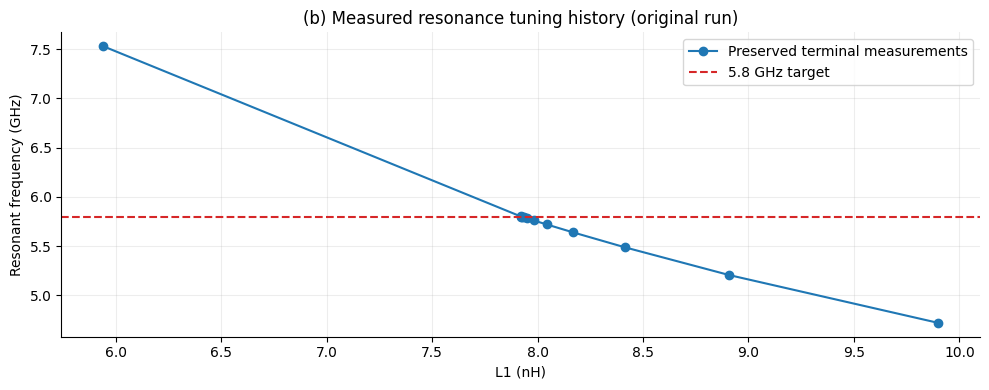

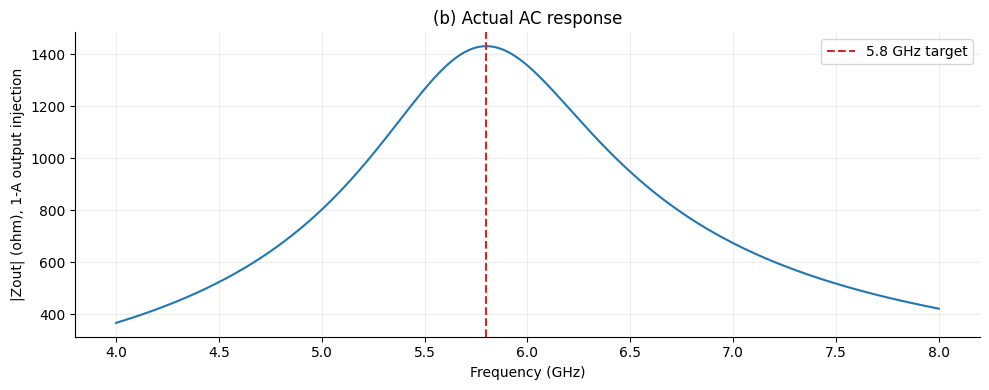

In [7]:
if EXECUTION_MODE == "review":
    show_part("b")